In [ ]:
! pip install kaggle

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Downloading the dataset

In [ ]:
! kaggle competitions download -c challenges-in-representation-learning-facial-expression-recognition-challenge

100% 285M/285M [00:02<00:00, 110MB/s] 
100% 285M/285M [00:02<00:00, 115MB/s]


In [ ]:
! unzip /content/drive/MyDrive/Capstone_Project_Data/challenges-in-representation-learning-facial-expression-recognition-challenge.zip

Archive:  /content/drive/MyDrive/Capstone_Project_Data/challenges-in-representation-learning-facial-expression-recognition-challenge.zip
  inflating: example_submission.csv  
  inflating: fer2013.tar.gz          
  inflating: icml_face_data.csv      
  inflating: test.csv                
  inflating: train.csv               


In [ ]:
# END OF DOWNLOADING DATASET

In [ ]:
import pandas as pd
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from mlxtend.plotting import plot_confusion_matrix

from keras import models
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from keras.optimizers import RMSprop,Adam
from keras.utils import to_categorical
from tensorflow.keras.models import load_model


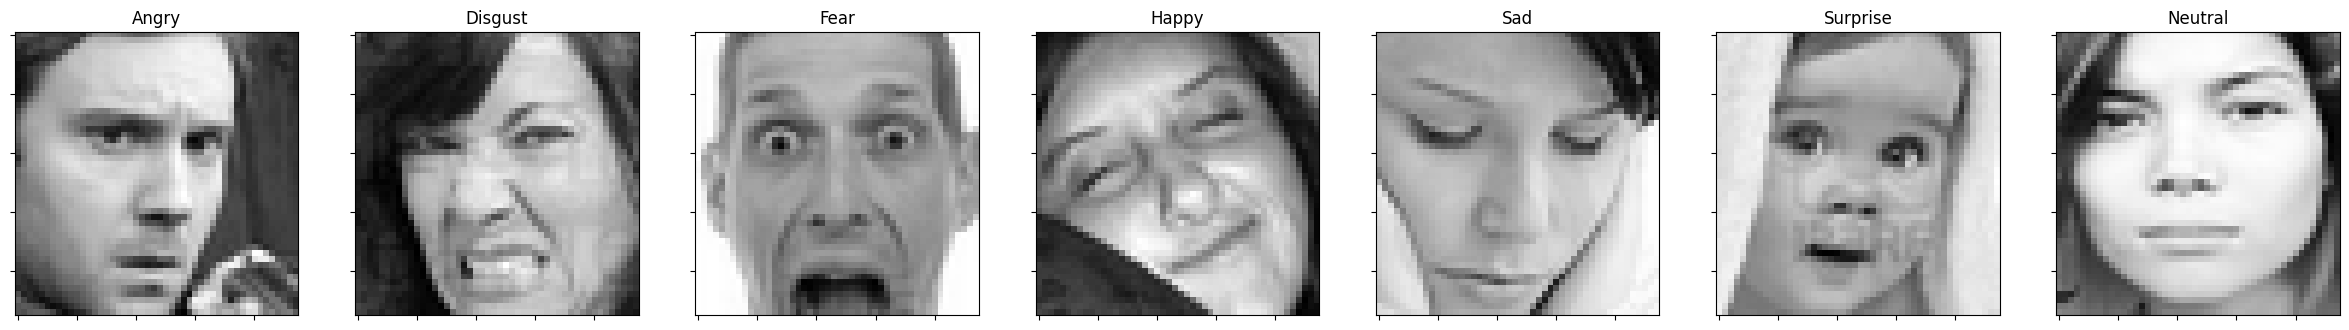

In [ ]:
# Read and load the dataset
path = "/content/drive/MyDrive/Capstone_Project_Data/"
data = pd.read_csv(path+"icml_face_data.csv")
data.head()

# Developing helper functions to prepare and plot the data
def prepare_data(data):
    """ Prepare data for modeling
        input: data frame with labels und pixel data
        output: image and label array """

    image_array = np.zeros(shape=(len(data), 48, 48))
    image_label = np.array(list(map(int, data['emotion'])))

    for i, row in enumerate(data.index):
        image = np.fromstring(data.loc[row, ' pixels'], dtype=int, sep=' ')
        image = np.reshape(image, (48, 48))
        image_array[i] = image

    return image_array, image_label

def plot_examples(label=0):
    fig, axs = plt.subplots(1, 5, figsize=(25, 12))
    fig.subplots_adjust(hspace = .2, wspace=.2)
    axs = axs.ravel()
    for i in range(5):
        idx = data[data['emotion']==label].index[i]
        axs[i].imshow(train_images[idx][:,:,0], cmap='gray')
        axs[i].set_title(emotions[train_labels[idx].argmax()])
        axs[i].set_xticklabels([])
        axs[i].set_yticklabels([])

def plot_all_emotions():
    fig, axs = plt.subplots(1, 7, figsize=(30, 12))
    fig.subplots_adjust(hspace = .2, wspace=.2)
    axs = axs.ravel()
    for i in range(7):
        idx = data[data['emotion']==i].index[i]
        axs[i].imshow(train_images[idx][:,:,0], cmap='gray')
        axs[i].set_title(emotions[train_labels[idx].argmax()])
        axs[i].set_xticklabels([])
        axs[i].set_yticklabels([])

def plot_image_and_emotion(test_image_array, test_image_label, pred_test_labels, image_number):
    """ Function to plot the image and compare the prediction results with the label """

    fig, axs = plt.subplots(1, 2, figsize=(12, 6), sharey=False)

    bar_label = emotions.values()

    axs[0].imshow(test_image_array[image_number], 'gray')
    axs[0].set_title(emotions[test_image_label[image_number]])

    axs[1].bar(bar_label, pred_test_labels[image_number], color='orange', alpha=0.7)
    axs[1].grid()

    plt.show()

def plot_compare_distributions(array1, array2, title1='', title2=''):
    df_array1 = pd.DataFrame()
    df_array2 = pd.DataFrame()
    df_array1['emotion'] = array1.argmax(axis=1)
    df_array2['emotion'] = array2.argmax(axis=1)

    fig, axs = plt.subplots(1, 2, figsize=(12, 6), sharey=False)
    x = emotions.values()

    y = df_array1['emotion'].value_counts()
    keys_missed = list(set(emotions.keys()).difference(set(y.keys())))
    for key_missed in keys_missed:
        y[key_missed] = 0
    axs[0].bar(x, y.sort_index(), color='orange')
    axs[0].set_title(title1)
    axs[0].grid()

    y = df_array2['emotion'].value_counts()
    keys_missed = list(set(emotions.keys()).difference(set(y.keys())))
    for key_missed in keys_missed:
        y[key_missed] = 0
    axs[1].bar(x, y.sort_index())
    axs[1].set_title(title2)
    axs[1].grid()

    plt.show()

# Define the emotions we would be focusing on
emotions = {0: 'Angry', 1: 'Disgust', 2: 'Fear', 3: 'Happy', 4: 'Sad', 5: 'Surprise', 6: 'Neutral'}

# Seperate the training data, test data and the validation data
train_image_array, train_image_label = prepare_data(data[data[' Usage'] == 'Training'])
test_image_array, test_image_label = prepare_data(data[data[' Usage'] == 'PublicTest'])
validation_image_array, validation_image_label = prepare_data(data[data[' Usage'] == 'PrivateTest'])

# Reshape and scale the images
train_images_data = train_image_array.reshape((train_image_array.shape[0], 48, 48, 1))
test_images_data = test_image_array.reshape((test_image_array.shape[0], 48, 48, 1))
validation_images_data = validation_image_array.reshape((validation_image_array.shape[0], 48, 48, 1))

train_images = train_images_data.astype('float32') / 255
test_images = test_images_data.astype('float32') / 255
validation_images = validation_images_data.astype('float32') / 255

# Encoding of the target value
train_labels = to_categorical(train_image_label)
test_labels = to_categorical(test_image_label)
validation_labels = to_categorical(validation_image_label)

plot_all_emotions()


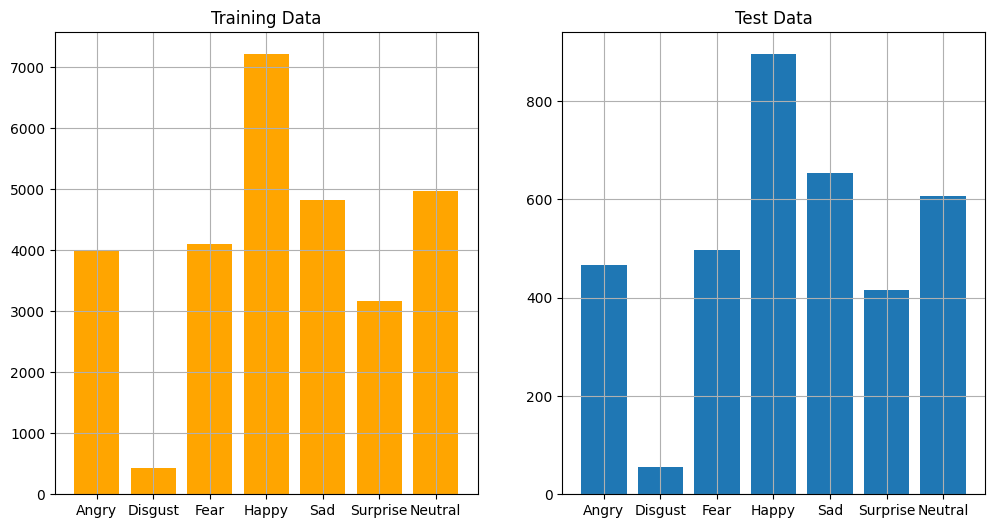

{0: 0.1391549688251071,
 1: 0.01518687519593159,
 2: 0.14270786164617366,
 3: 0.2513149186666202,
 4: 0.16823992476226968,
 5: 0.11045316799609878,
 6: 0.17294228290779895}

In [ ]:
# Compare the distribution of the training data
plot_compare_distributions(train_labels, test_labels, 'Training Data', 'Test Data')

# Compute class weights to handle class imbalance
class_weight = dict(zip(range(0, 7), (((data[data[' Usage']=='Training']['emotion'].value_counts()).sort_index())/len(data[data[' Usage']=='Training']['emotion'])).tolist()))
class_weight

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Define the CNN model
model = Sequential()

# Convolutional Block 1
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(48, 48, 1)))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

# Convolutional Block 2
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

# Convolutional Block 3
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

# Fully Connected Layers
model.add(Flatten())
model.add(Dense(1024, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(7, activation='softmax'))  # 7 classes for emotions

# Define the learning rate
learning_rate = 0.0001

# Compile the CNN model with a specified learning rate
model.compile(optimizer=Adam(learning_rate=learning_rate),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Display the updated model's architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 46, 46, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 23, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 23, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 21, 21, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 10, 10, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 10, 10, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 4, 4, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 4, 4, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1024)                │       2,098,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 7)                   │           7,175 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,198,023 (8.38 MB)

 Trainable params: 2,198,023 (8.38 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.2457 - loss: 1.8233 - val_accuracy: 0.3441 - val_loss: 1.6970
Epoch 2/50
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3520 - loss: 1.6512 - val_accuracy: 0.4099 - val_loss: 1.5473
Epoch 3/50
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4069 - loss: 1.5381 - val_accuracy: 0.4466 - val_loss: 1.4507
Epoch 4/50
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4393 - loss: 1.4578 - val_accuracy: 0.4714 - val_loss: 1.3883
Epoch 5/50
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4605 - loss: 1.4122 - val_accuracy: 0.4901 - val_loss: 1.3409
Epoch 6/50
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4797 - loss: 1.3613 - val_accuracy: 0.5046 - val_loss: 1.3031
Epoch 7/50
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5013 - loss: 1.3123 - val_accuracy: 0.5110 - val_loss: 1.2641
Epoch 8/50
1795/1795 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5109 - loss: 1.2870 -

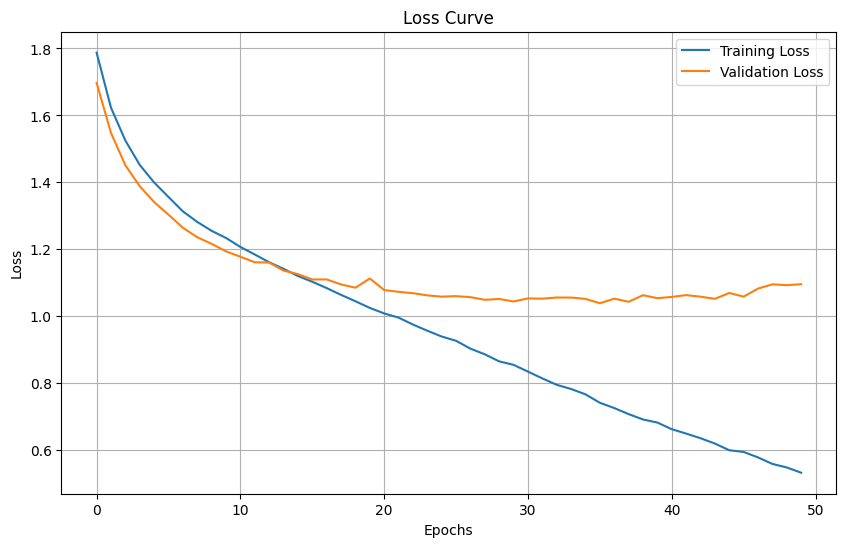

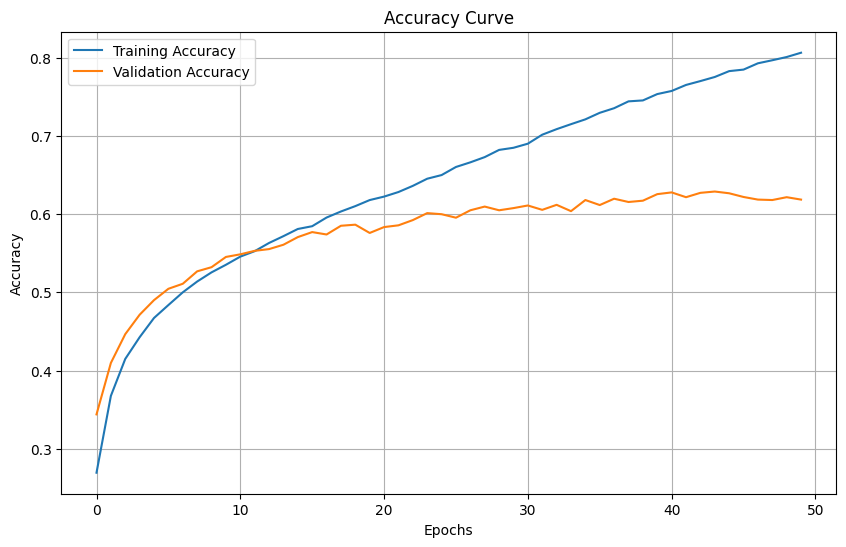

In [ ]:
# Import required libraries
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Add early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

# Train the CNN model with updated parameters
history = model.fit(train_images, train_labels,
                    validation_data=(validation_images, validation_labels),
                    epochs=50,  # Reduced epochs
                    batch_size=16,  # Updated batch size
                    callbacks=[early_stopping])

# Evaluate the model on the test data
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f'Test Accuracy: {test_acc:.2f}')

# Plot the updated loss and validation loss curves
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot the updated accuracy and validation accuracy curves
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Commenting out the save so that it does not overwrite the saved trained data
model.save('/content/drive/MyDrive/Capstone_Project_Data/emotion_recognition_model.h5')
